## KMA/MSM 2026/2027 - Úloha 2

### Téma: Testy o poloze — jednovýběrové, dvouvýběrové a vícevýběrové testy, ANOVA, vícerozměrné testy

#### Zvolený dataset: Fish Market (https://www.kaggle.com/datasets/aungpyaeap/fish-market, https://github.com/Ankit152/Fish-Market/blob/main/Fish.csv)

In [43]:
import pandas as pd
df = pd.read_csv('Fish.csv')
df = df[df['Weight'] > 0]  # odstranění chybného pozorování s Weight = 0
df['Species'].value_counts()

Species
Perch        56
Bream        35
Roach        19
Pike         17
Smelt        14
Parkki       11
Whitefish     6
Name: count, dtype: int64

In [44]:
variables = ['Length3', 'Height', 'Weight']
alpha = 0.05
# vybrány pouze čtyři nejpočetnější druhy u kterých má smysl porovnávat fyzické vlastnosti
classes = ['Bream', 'Perch', 'Roach', 'Pike']
groups = {s: df[df['Species'] == s] for s in classes}
group_a = groups['Bream']   # hlavní skupina pro jednovýběrové testy (vysoký počet pozorování + ve všech proměnných vyhovuje testu normality)

df.head()

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


### Test normality - Shapiro-Wilk test

Nulová hypotéza ($H_0$): Data pocházejí z normálního rozdělení.
Alternativní hypotéza ($H_1$): Data nepocházejí z normálního rozdělení.

Použitý Shapiro-Wilk test má zde omezenou sílu a nezamítnutí $H_0$ není důkazem normality.

In [45]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

rows = []
for s in classes:
    for var in variables:
        w, p = stats.shapiro(groups[s][var])
        rows.append({'Druh': s, 'Proměnná': var, 'n': len(groups[s]), 'Testová statistika': round(w, 4), 'p-hodnota': p, 'Závěr': 'nezamítáme H0' if p > alpha else 'zamítáme H0'})


pd.DataFrame(rows).style.format({'p-hodnota': '{:.4f}'}).hide(axis='index')

Druh,Proměnná,n,Testová statistika,p-hodnota,Závěr
Bream,Length3,35,0.983900,0.8763,nezamítáme H0
Bream,Height,35,0.970200,0.4483,nezamítáme H0
Bream,Weight,35,0.959200,0.2169,nezamítáme H0
Perch,Length3,56,0.935800,0.0052,zamítáme H0
Perch,Height,56,0.907900,0.0004,zamítáme H0
Perch,Weight,56,0.816800,0.0000,zamítáme H0
Roach,Length3,19,0.977000,0.9023,nezamítáme H0
Roach,Height,19,0.966200,0.6988,nezamítáme H0
Roach,Weight,19,0.898000,0.0448,zamítáme H0
Pike,Length3,17,0.924200,0.1739,nezamítáme H0


#### QQ grafy a histogramy

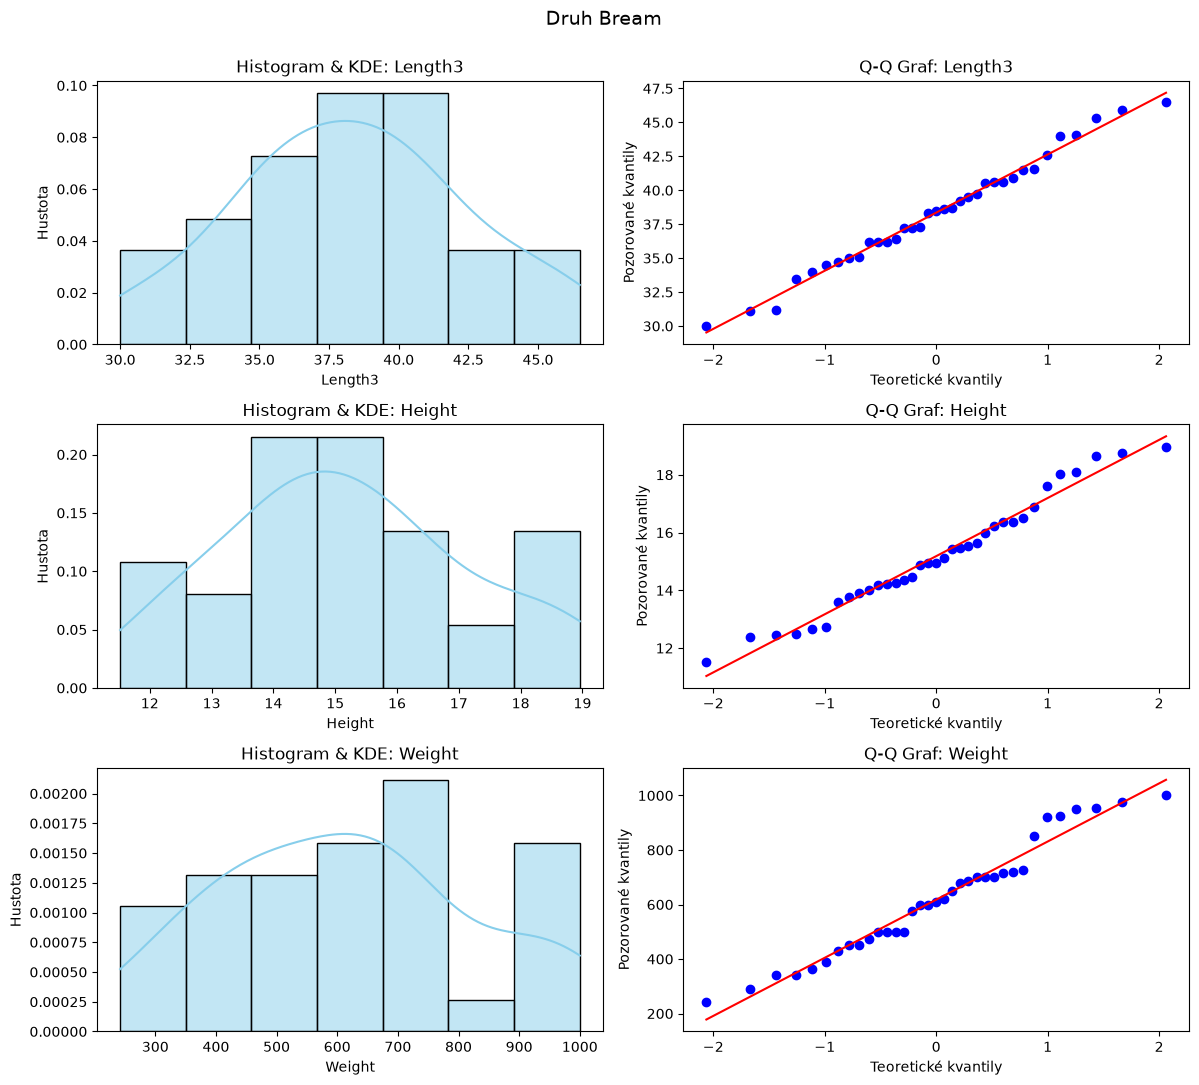

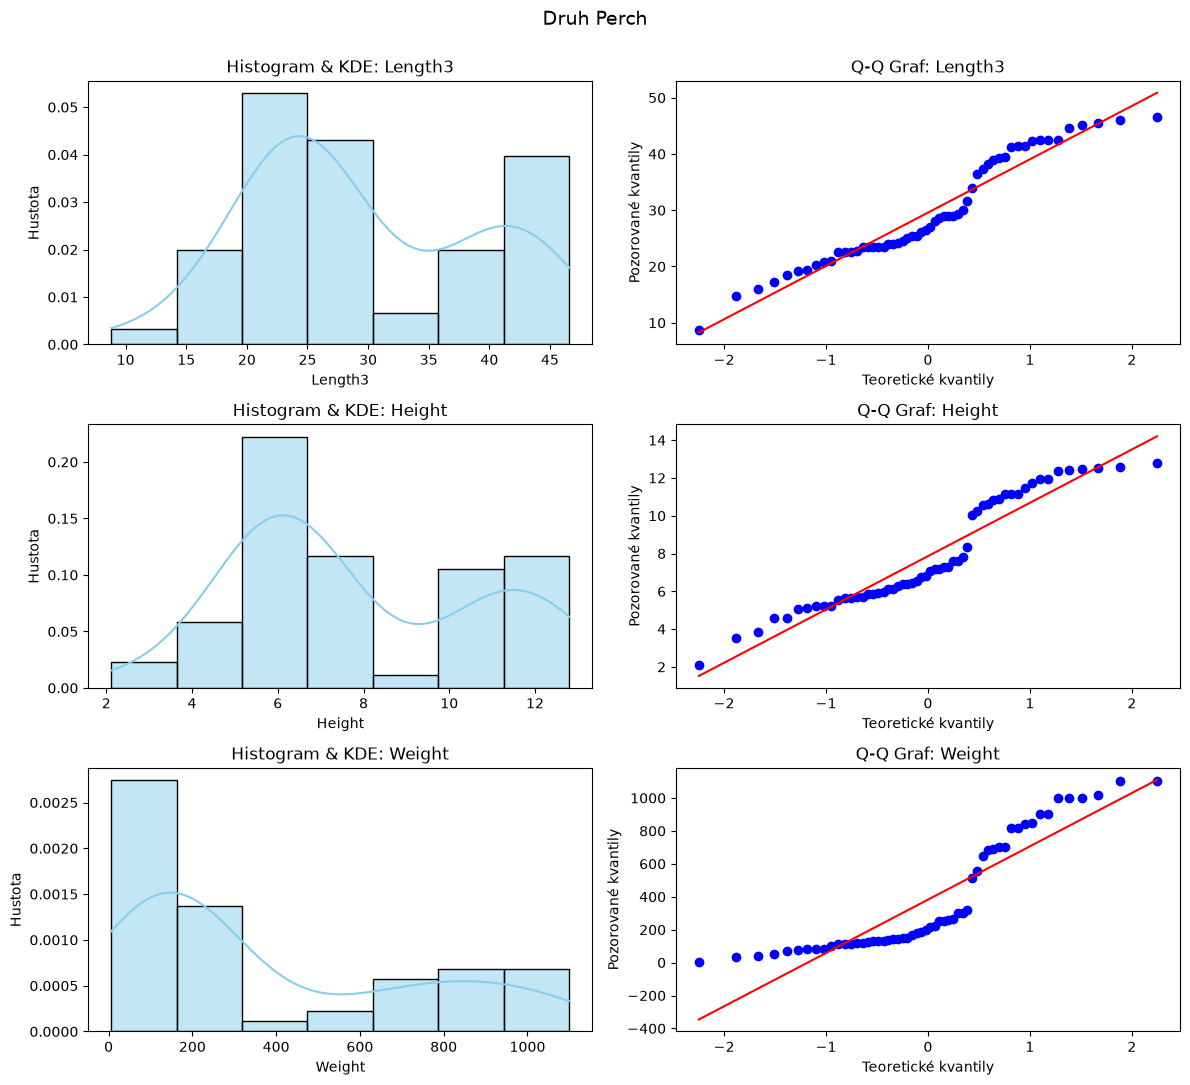

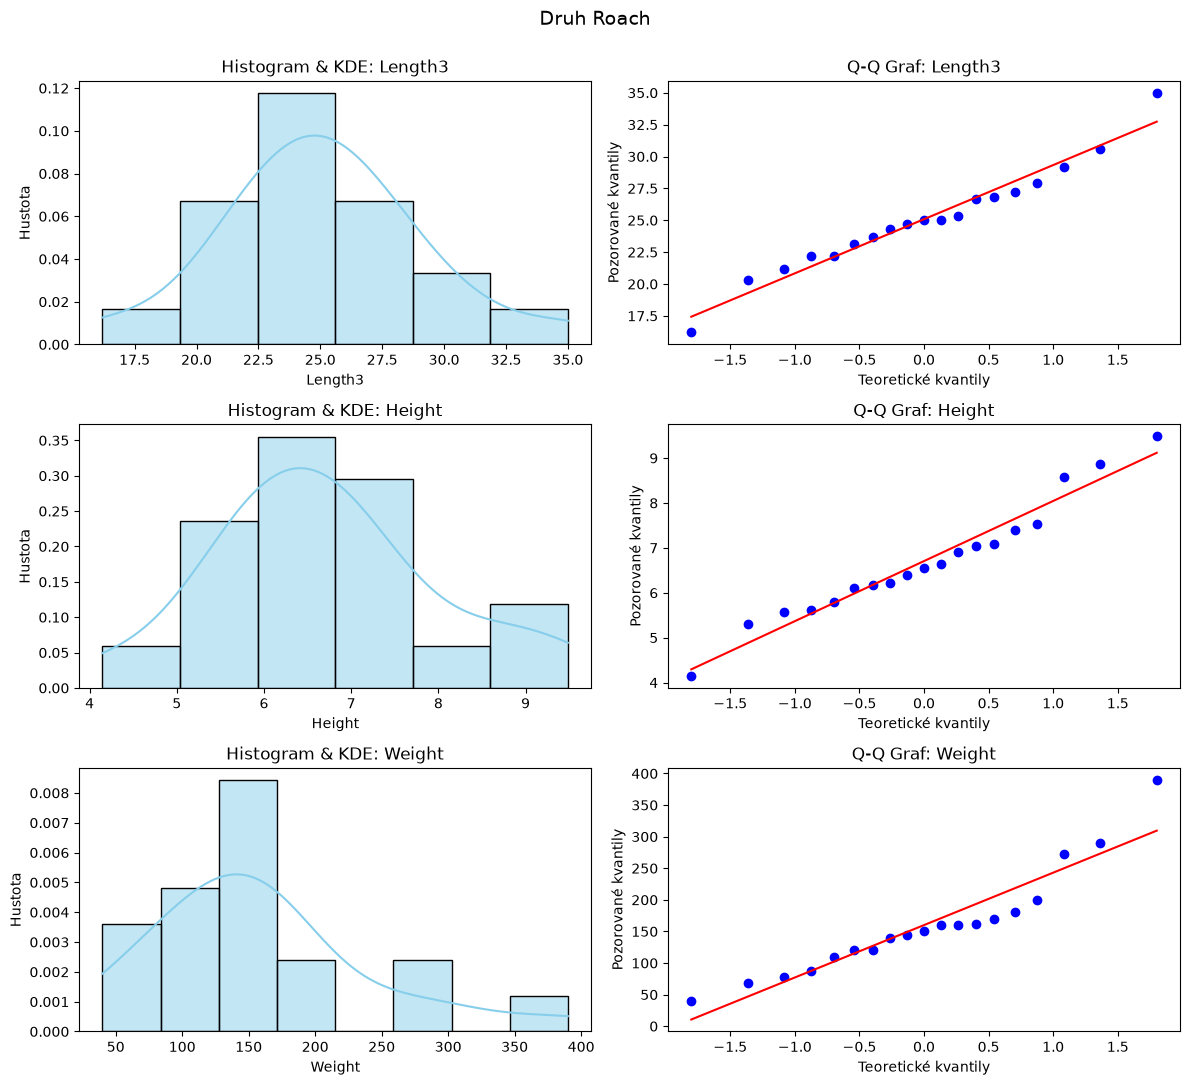

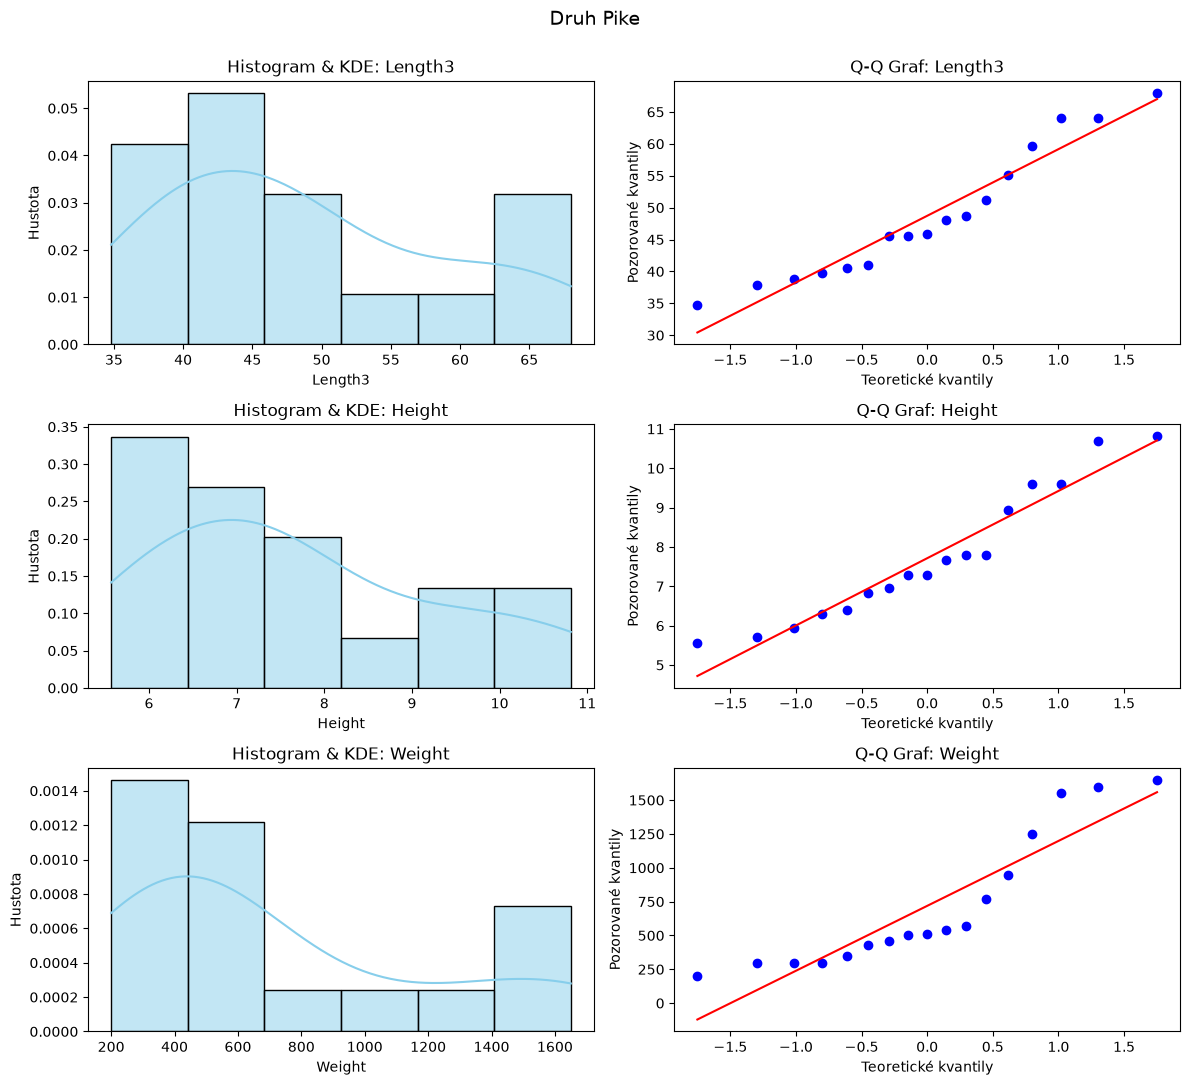

In [46]:
for s in ['Bream', 'Perch', 'Roach', 'Pike']:
    fig, axes = plt.subplots(len(variables), 2, figsize=(12, 3.6 * len(variables)))
    fig.suptitle(f'Druh {s}', y=1.0, fontsize=14)

    for i, var in enumerate(variables):
        data = groups[s][var]

        sns.histplot(data, kde=True, ax=axes[i, 0], color='skyblue', stat='density')
        axes[i, 0].set_title(f'Histogram & KDE: {var}')
        axes[i, 0].set_xlabel(var)
        axes[i, 0].set_ylabel('Hustota')

        stats.probplot(data, dist='norm', plot=axes[i, 1])
        axes[i, 1].set_title(f'Q-Q Graf: {var}')
        axes[i, 1].set_xlabel('Teoretické kvantily')
        axes[i, 1].set_ylabel('Pozorované kvantily')

    plt.tight_layout()
    plt.show()

Shapiro-Wilk test nezamítá normalitu u druhu Bream v žádné ze tří proměnných, proto jej používáme jako hlavní skupinu pro jednovýběrové testy. U druhů Roach a Pike normalitu nezamítáme pro `Length3` a `Height`, ale zamítáme ji pro proměnnou `Weight`. U druhu Perch zamítáme normalitu ve všech třech proměnných. Q-Q grafy ukazují, že Perch a Pike mají sešikmené rozdělení a rozhodně nepřipomínají normálně rozdělený dataset.


### Jednovýběrové testy

#### Jako parametrický test je vždy zvolen Jednovýběrový t-test, jako neparametrický test Wilcoxonův test

Proměnná `Height`:
Ověřujeme, zda se výška těla jedinců druhu Bream statisticky významně odlišuje od průměru celého datasetu (všech druhů dohromady).
* **Parametrická hypotéza:**
  * $H_0: \mu = \mu_0$ (Průměrná výška těla u druhu Bream je rovna celkovému průměru datasetu)
  * $H_1: \mu \neq \mu_0$ (Průměrná výška těla u druhu Bream se liší od celkového průměru)
* **Neparametrická hypotéza:**
  * $H_0: m = m_0$ (Medián výšky těla u druhu Bream je roven celkovému mediánu datasetu)
  * $H_1: m \neq m_0$ (Medián výšky těla u druhu Bream se liší od celkového mediánu)

Proměnná `Length3`:
Testujeme, zda se průměrná délka ryb druhu Bream liší od referenční hodnoty $40\,\text{cm}$. Hodnota je zvolena pouze orientačně (uvádí se délka 30-55 cm)
* **Parametrická hypotéza:**
  * $H_0: \mu = 40\text{ cm}$ (Průměrná délka ve skupině Bream je rovna $40\text{ cm}$)
  * $H_1: \mu \neq 40\text{ cm}$ (Průměrná délka ve skupině Bream se liší od $40\text{ cm}$)
* **Neparametrická hypotéza:**
  * $H_0: m = 40\text{ cm}$ (Medián délky ve skupině Bream je roven $40\text{ cm}$)
  * $H_1: m \neq 40\text{ cm}$ (Medián délky ve skupině Bream se liší od $40\text{ cm}$)

Proměnná `Weight`:
Testujeme, zda se průměrná hmotnost ryb druhu Bream liší od referenční hodnoty $\mu_0 = 600\text{ g}$ (opět ilustračně zvolená hodnota, nikoli oficiální údaj).
* **Parametrická hypotéza:**
  * $H_0: \mu = 600\text{ g}$ (Průměrná hmotnost ve skupině Bream je rovna $600\text{ g}$)
  * $H_1: \mu \neq 600\text{ g}$ (Průměrná hmotnost ve skupině Bream se liší od $600\text{ g}$)
* **Neparametrická hypotéza:**
  * $H_0: m = 600\text{ g}$ (Medián hmotnosti ve skupině Bream je roven $600\text{ g}$)
  * $H_1: m \neq 600\text{ g}$ (Medián hmotnosti ve skupině Bream se liší od $600\text{ g}$)


In [47]:
data_h = group_a['Height']
mu0_h = df['Height'].mean()
m0_h = df['Height'].median()

t_stat_h, p_val_t_h = stats.ttest_1samp(data_h, popmean=mu0_h)
w_stat_h, p_val_w_h = stats.wilcoxon(data_h - m0_h)

print(f"Height: Výběrový průměr = {data_h.mean():.4f} vs. mu_0 = {mu0_h:.4f} | t-test p = {p_val_t_h:.4e}")
print(f"Height: Výběrový medián = {data_h.median():.4f} vs. m_0 = {m0_h:.4f} | Wilcoxon p = {p_val_w_h:.4e}")


data_l = group_a['Length3']
ref_l = 40.0

t_stat_l, p_val_t_l = stats.ttest_1samp(data_l, popmean=ref_l)
w_stat_l, p_val_w_l = stats.wilcoxon(data_l - ref_l)

print(f"Length3: Výběrový průměr = {data_l.mean():.4f} cm vs. {ref_l} cm | t-test p = {p_val_t_l:.4e}")
print(f"Length3: Výběrový medián = {data_l.median():.4f} cm vs. {ref_l} cm | Wilcoxon p = {p_val_w_l:.4e}")


data_w = group_a['Weight']
ref_w = 600.0

t_stat_w, p_val_t_w = stats.ttest_1samp(data_w, popmean=ref_w)
w_stat_w, p_val_w_w = stats.wilcoxon(data_w - ref_w)

print(f"Weight: Výběrový průměr = {data_w.mean():.4f} g vs. {ref_w} g | t-test p = {p_val_t_w:.4e}")
print(f"Weight: Výběrový medián = {data_w.median():.4f} g vs. {ref_w} g | Wilcoxon p = {p_val_w_w:.4e}")

Height: Výběrový průměr = 15.1832 vs. mu_0 = 8.9868 | t-test p = 1.9472e-19
Height: Výběrový medián = 14.9544 vs. m_0 = 7.7890 | Wilcoxon p = 5.8208e-11
Length3: Výběrový průměr = 38.3543 cm vs. 40.0 cm | t-test p = 2.5198e-02
Length3: Výběrový medián = 38.5000 cm vs. 40.0 cm | Wilcoxon p = 3.6004e-02
Weight: Výběrový průměr = 617.8286 g vs. 600.0 g | t-test p = 6.1739e-01
Weight: Výběrový medián = 610.0000 g vs. 600.0 g | Wilcoxon p = 7.8844e-01


Proměnná `Height`:
Oba testy zamítají $H_0$. Průměrná výška těla u druhu Bream je výrazně vyšší než průměr celého datasetu, stejně tak medián.

Proměnná `Length3`:
Oba testy rovněž zamítají $H_0$, i když rozdíl již není tak výrazný jako u proměnné `Height`.

Proměnná `Weight`:
Nezamítáme $H_0$ u žádného z testů. Průměr 617,8 g a medián 610 g jsou blízko referenci $600\,\text{g}$. Nezamítnutí neznamená, že je střední hodnota přesně $600\,\text{g}$, jen že data odchylku neprokazují.

### Dvouvýběrové testy

Pro každou ze tří proměnných porovnáváme polohu mezi všemi dvojicemi druhů (6 dvojic).

* **Parametrický přístup:** Dvouvýběrový Welch t-test.
  * $H_0: \mu_i = \mu_j$ (Střední hodnoty dané proměnné se u druhů $i$ a $j$ rovnají)
  * $H_1: \mu_i \neq \mu_j$ (Střední hodnoty dané proměnné se u druhů $i$ a $j$ liší)
* **Neparametrický přístup:** Mann-Whitney U test.
  * $H_0$: Rozdělení proměnné jsou u druhů $i$ a $j$ shodná
  * $H_1$: Rozdělení proměnné se u druhů $i$ a $j$ liší

In [48]:
from itertools import combinations


pairs = list(combinations(classes, 2))

rows = []
for var in variables:
    for g1, g2 in pairs:
        d1, d2 = groups[g1][var], groups[g2][var]
        p_w = stats.ttest_ind(d1, d2, equal_var=False).pvalue
        p_mw = stats.mannwhitneyu(d1, d2, alternative='two-sided').pvalue
        rows.append({
            'Proměnná': var,
            'Dvojice': f'{g1} vs {g2}',
            'Průměr 1': d1.mean(),
            'Průměr 2': d2.mean(),
            'p (Welch)': p_w,
            'Welch: zamítáme H0': 'ano' if p_w < alpha else 'ne',
            'p (MW-U)': p_mw,
            'MW-U: zamítáme H0': 'ano' if p_mw < alpha else 'ne',
        })

res = pd.DataFrame(rows)

num_cols = ['Průměr 1', 'Průměr 2', 'p (Welch)', 'p (MW-U)']
res.style.format({c: '{:.4g}' for c in num_cols}).hide(axis='index')

Proměnná,Dvojice,Průměr 1,Průměr 2,p (Welch),Welch: zamítáme H0,p (MW-U),MW-U: zamítáme H0
Length3,Bream vs Perch,38.35,29.57,4.433e-08,ano,4.357e-05,ano
Length3,Bream vs Roach,38.35,25.08,1.301e-13,ano,4.61e-09,ano
Length3,Bream vs Pike,38.35,48.72,0.0007197,ano,0.0001165,ano
Length3,Perch vs Roach,29.57,25.08,0.00606,ano,0.1454,ne
Length3,Perch vs Pike,29.57,48.72,3.028e-07,ano,5.539e-07,ano
Length3,Roach vs Pike,25.08,48.72,1.513e-08,ano,3.951e-07,ano
Height,Bream vs Perch,15.18,7.862,6.658e-25,ano,6.882e-15,ano
Height,Bream vs Roach,15.18,6.706,1.636e-24,ano,1.814e-09,ano
Height,Bream vs Pike,15.18,7.714,1.212e-16,ano,6.883e-09,ano
Height,Perch vs Roach,7.862,6.706,0.02027,ano,0.3208,ne


#### Vizualizace spočítaných hodnot:

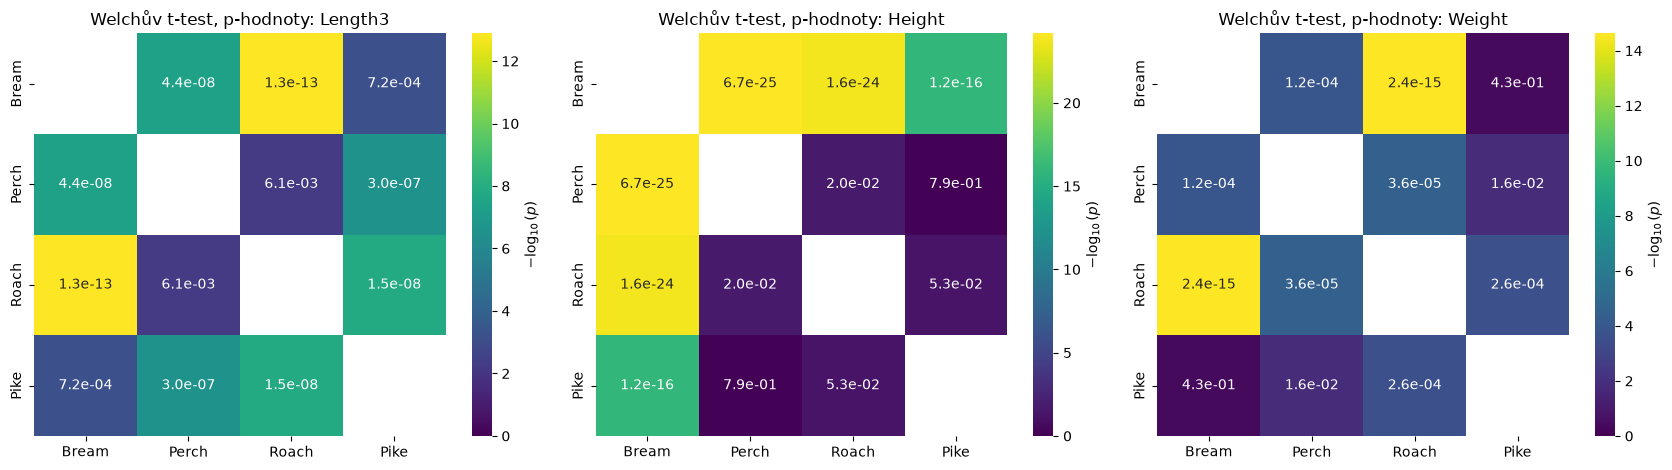

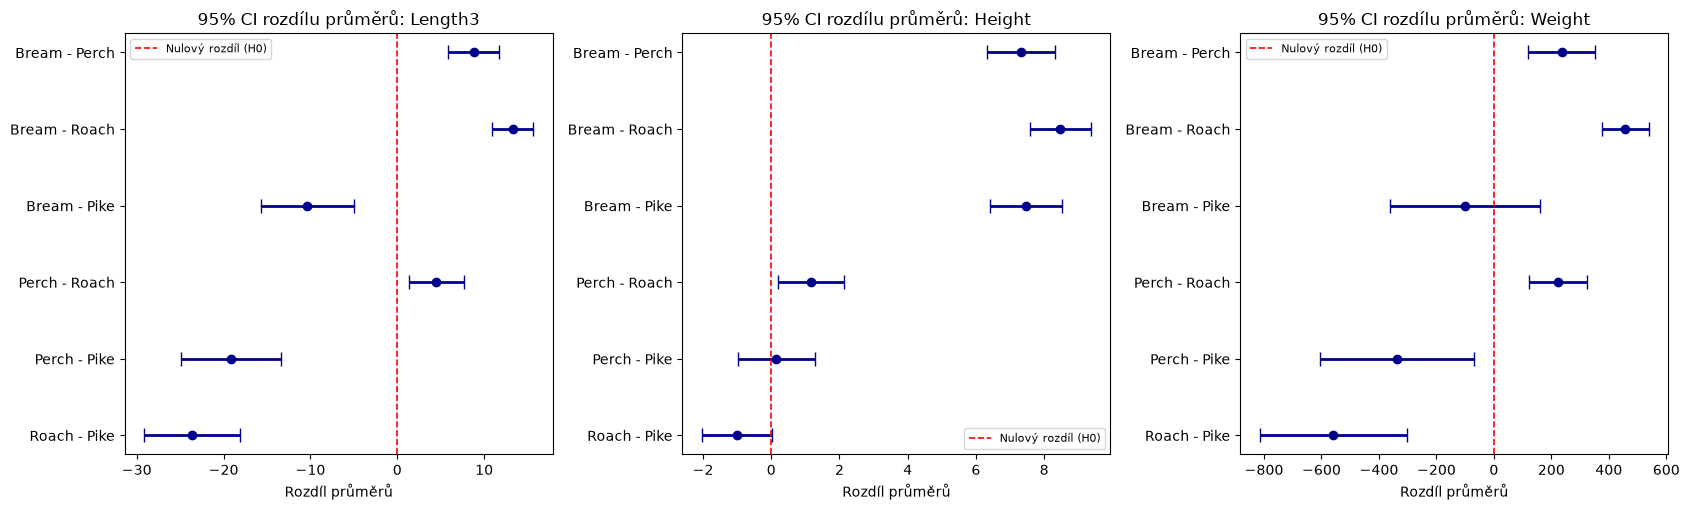

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

for idx, var in enumerate(variables):
    p_mat = pd.DataFrame(np.nan, index=classes, columns=classes)

    for g1, g2 in pairs:
        p = res[(res['Proměnná'] == var) & (res['Dvojice'] == f'{g1} vs {g2}')]['p (Welch)'].iloc[0]
        p_mat.loc[g1, g2] = p_mat.loc[g2, g1] = p

    score = -np.log10(p_mat.clip(lower=1e-300))
    annot = np.array([[('' if np.isnan(p) else f'{p:.1e}') for p in row] for row in p_mat.values])

    sns.heatmap(score, annot=annot, fmt='', mask=p_mat.isna(), cmap='viridis', vmin=0, cbar=True, cbar_kws={'label': r'$-\log_{10}(p)$'}, ax=axes[idx])
    axes[idx].set_title(f'Welchův t-test, p-hodnoty: {var}')

plt.tight_layout()
plt.show()

#95% intervaly sploehlivosti pro všechny dvojice
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

for idx, var in enumerate(variables):
    labels, diffs, lows, highs = [], [], [], []

    for g1, g2 in pairs:
        d1, d2 = groups[g1][var], groups[g2][var]

        ci = stats.ttest_ind(d1, d2, equal_var=False).confidence_interval(confidence_level=0.95)

        labels.append(f'{g1} - {g2}')
        diffs.append(d1.mean() - d2.mean())
        lows.append(ci.low)
        highs.append(ci.high)

    y = np.arange(len(labels))
    xerr = [np.array(diffs) - np.array(lows), np.array(highs) - np.array(diffs)]

    axes[idx].errorbar(diffs, y, xerr=xerr, fmt='o', color='darkblue', capsize=5, linewidth=2)
    axes[idx].axvline(0, color='red', linestyle='--', linewidth=1.2, label='Nulový rozdíl (H0)')
    axes[idx].set_yticks(y)
    axes[idx].set_yticklabels(labels)
    axes[idx].invert_yaxis()
    axes[idx].set_title(f'95% CI rozdílu průměrů: {var}')
    axes[idx].set_xlabel('Rozdíl průměrů')
    axes[idx].legend(loc='best', fontsize=8)

plt.tight_layout()
plt.show()

Vidíme, že druhy se vzájemně liší od ostatních a většina nulových hypotéz zůstává zamítnuta. Protože data u druhů Perch a Pike jsou zešikmená a nesplňují předpoklad normality, je nutné vzít výsledky parametrického testu s rezervou a zaměřit se spíše na Mann-Whitneyův U test, který  odhalil, že rozdíly mezi druhy Perch a Roach nejsou ani u jedné z měřených proměnných statisticky významné, ačkoliv Welchův test je jako významné označil. Druh Bream se výrazně liší od ostatních u proměnné `Height`, což potvrzují velmi nízké p-hodnoty i vykreslený interval spolehlivosti. Celkově testy ukazují že všechny druhy ryb se od sebe nějakým způsobem liší.



### Vícevýběrové testy a post-hoc analýza

Vzhledem k tomu, že u většiny sledovaných proměnných není splněn předpoklad normality dat, byl pro porovnání více skupin (druhů ryb) místo ANOVY zvolen neparametrický Kruskal-Wallisův test.

- **Hypotézy testu:**
  - $H_0$: Všechny sledované skupiny pocházejí ze stejného rozdělení (mediány skupin se statisticky významně neliší).
  - $H_1$: Alespoň jedna skupina má rozdělení posunuté oproti ostatním (minimálně dvě skupiny se statisticky významně liší).

Následuje párové mnohonásobné porovnání s použitím **Dunnova post-hoc testu** s **Holmovou korekcí** pro korekci p-hodnot.

- **Párové hypotézy pro post-hoc analýzu:**
  - $H_0$: Rozdělení hodnot mezi druhy $i$ a $j$ je shodné ($m_i = m_j$).
  - $H_1$: Mezi druhy $i$ a $j$ existuje statisticky významný posun v rozdělení ($m_i \neq m_j$).


In [50]:
from scipy.stats import kruskal
import scikit_posthocs as sp

for var in variables:
    stat, p_value = kruskal(
        groups['Bream'][var],
        groups['Perch'][var],
        groups['Roach'][var],
        groups['Pike'][var]
    )
    print(f"{var}: H = {stat:.4f}, p-hodnota = {p_value:.4e}")



Length3: H = 54.1743, p-hodnota = 1.0300e-11
Height: H = 74.3300, p-hodnota = 5.0432e-16
Weight: H = 38.7146, p-hodnota = 1.9949e-08


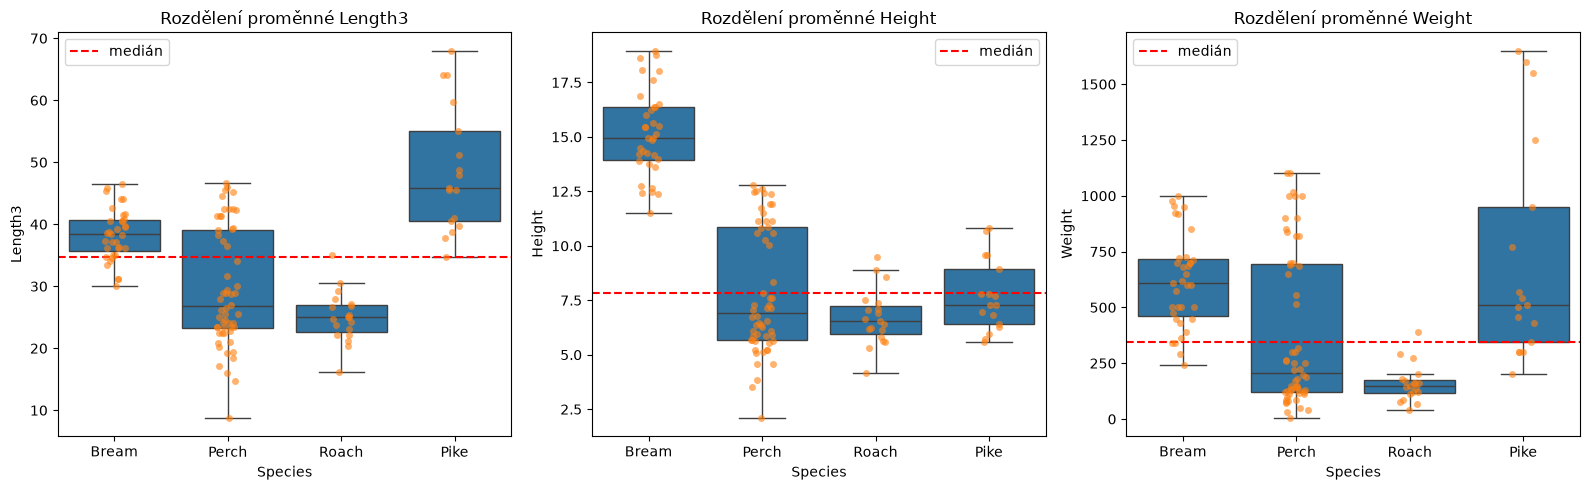

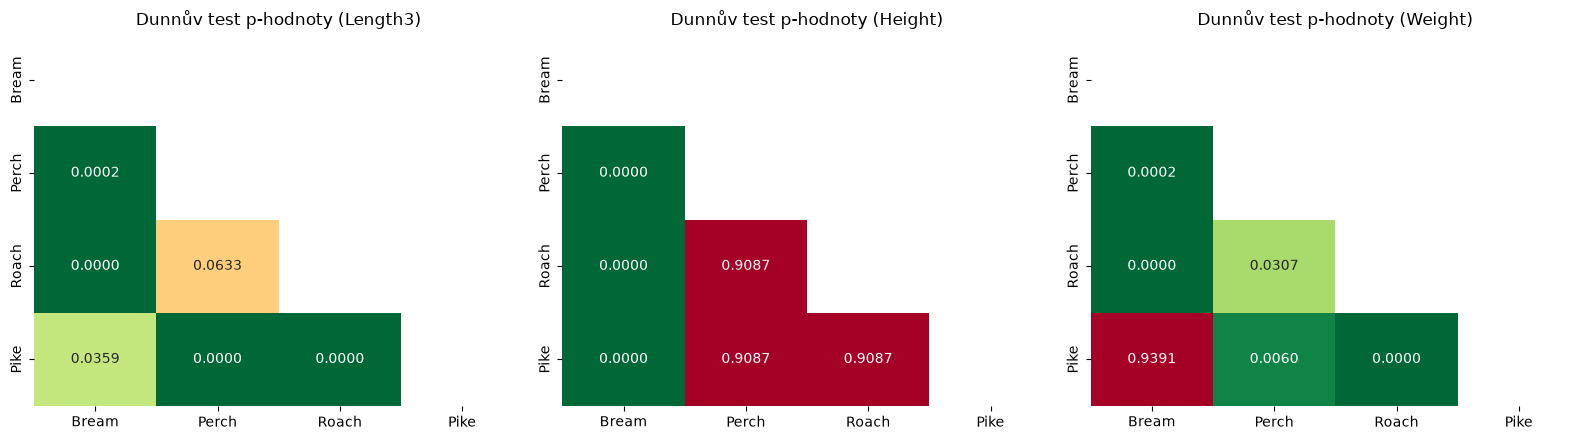

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# boxploty + body
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
df_sub = df[df['Species'].isin(classes)]
for ax, var in zip(axes, variables):
    sns.boxplot(data=df_sub, x='Species', y=var, order=classes, ax=ax, showfliers=False)
    sns.stripplot(data=df_sub, x='Species', y=var, order=classes, ax=ax, alpha=0.6)
    
    ax.axhline(df_sub[var].median(), color='red', linestyle='--', label='medián')
    ax.set_title(f'Rozdělení proměnné {var}')
    ax.legend()

plt.tight_layout()
plt.show()

# heatmapy Dunnova post-hoc testu s Holmovou korekcí
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, var in zip(axes, variables):
    dunn_res = sp.posthoc_dunn(df_sub, val_col=var, group_col='Species', p_adjust='holm').loc[classes, classes]
    mask = np.triu(np.ones_like(dunn_res, dtype=bool))  # jen dolní trojúhelník - odstranění duplicit
    
    sns.heatmap(
        dunn_res, mask=mask, annot=True, fmt=".4f",
        cmap="RdYlGn_r", vmin=0, vmax=0.1, cbar=False, ax=ax
    )
    ax.set_title(f'Dunnův test p-hodnoty ({var})')

plt.tight_layout()
plt.show()


Vícevýběrové testy potvrzují to, co je z vykreslených dat vidět pouhým okem, nulovou hypotézu Kruskal-Wallis testu o shodě rozdělení (polohy) ve všech skupinách jednoznačně zamítáme u všech tří proměnných. Alespoň jeden druh ryby se vždy v něčem statisticky významně liší od ostatních, což ovšem neznamená že při pohledu na proměnné zvlášť u post-hoc analýzy nemusí ke shodě dojít (`Weight` odděluje dva těžké druhy (Bream, Pike) od dvou lehčích (Perch, Roach) a `Height` jednoznačně odděluje jeden druh od ostatních) a u určitých dvojic hypotézu nemůžeme zamítnout. Výsledky odpovídají nalezeným údajům o daných rybách na internetu.

### Vícerozměrný přístup

Začneme Boxovým M-testem o shodě dvou variačních matic, což je předpoklad pro další testování.

In [52]:
def box_m(*groups):
    g = len(groups)
    k = groups[0].shape[1]
    ns = np.array([len(x) for x in groups])
    n = ns.sum()
    Ss = [np.cov(x, rowvar=False) for x in groups]
    Sp = sum((nj - 1) * Sj for nj, Sj in zip(ns, Ss)) / (n - g)
    M = (n - g) * np.linalg.slogdet(Sp)[1] - sum((nj - 1) * np.linalg.slogdet(Sj)[1] for nj, Sj in zip(ns, Ss))
    c = (2 * k**2 + 3 * k - 1) / (6 * (k + 1) * (g - 1)) * (np.sum(1 / (ns - 1)) - 1 / (n - g))
    stat = (1 - c) * M
    df = (g - 1) * k * (k + 1) / 2
    return M, stat, df, stats.chi2.sf(stat, df)


groups_dict = {
    sp: df[df['Species'] == sp][variables].dropna().to_numpy()
    for sp in classes
}

# porovnání kovariančních matic pro všechny dvojice
results = []
for sp1, sp2 in combinations(classes, 2):
    M, chi2_stat, df_val, p_val = box_m(groups_dict[sp1], groups_dict[sp2])
    results.append({
        'Dvojice': f'{sp1} vs {sp2}',
        'M': round(M, 2),
        'chi2': round(chi2_stat, 2),
        'df': int(df_val),
        'p-hodnota': p_val,
        'Shodné matice': 'ano' if p_val >= alpha else 'ne',
    })

df_box_pairs = pd.DataFrame(results)
display(df_box_pairs)

M_all, chi2_all, df_all, p_all = box_m(*groups_dict.values())
print(f"Pro všechny čtyři druhy najednou: M = {M_all:.2f}, chi2 = {chi2_all:.2f}, df = {int(df_all)}, p = {p_all:.3e}")

,Dvojice,M,chi2,df,p-hodnota,Shodné matice
0,Bream vs Perch,71.51,68.69,6,7.571970e-13,ne
1,Bream vs Roach,55.89,51.91,6,1.948025e-09,ne
2,Bream vs Pike,98.78,91.09,6,1.801609e-17,ne
3,Perch vs Roach,59.44,55.58,6,3.542608e-10,ne
4,Perch vs Pike,95.15,88.29,6,6.867466e-17,ne
5,Roach vs Pike,86.65,78.33,6,7.894124e-15,ne


Pro všechny čtyři druhy najednou: M = 263.48, chi2 = 248.50, df = 18, p = 1.649e-42


Protože u všech dvojic na základě testu $\Sigma_1 \ne \Sigma_2$, použijeme test o shodě dvou vektorů středních hodnot při rozdílných kovariancích (vícerozměrná obdoba Welchova testu):   
* $H_0: $ vektor středních hodnot je stejný ve všech skupinách
* $H_1: $ alespoň dva druhy se liší vektorem středních hodnot

In [53]:
from scipy.stats import chi2

def mean_value_equality(data1, data2):
    n1, k = data1.shape
    n2, _ = data2.shape
    x1_bar, x2_bar = data1.mean(axis=0), data2.mean(axis=0)
    S1 = np.cov(data1, rowvar=False)
    S2 = np.cov(data2, rowvar=False)
    diff = x1_bar - x2_bar
    Sigma_hat = S1 / n1 + S2 / n2
    T2 = diff @ np.linalg.solve(Sigma_hat, diff)
    p_value = chi2.sf(T2, df=k)
    return T2, k, p_value


results = []
for sp1, sp2 in combinations(classes, 2):
    d1, d2 = groups_dict[sp1], groups_dict[sp2]
    
    T2_diff, df_k, p_t2_diff = mean_value_equality(d1, d2)
    
    results.append({
        'Dvojice': f'{sp1} vs {sp2}',
        'T2': round(T2_diff, 2),
        'df (k)': df_k,
        'p-hodnota': p_t2_diff,
        'Zamítáme H0?': 'ano' if p_t2_diff < alpha else 'ne'
    })

df_hotelling_diff = pd.DataFrame(results)
display(df_hotelling_diff)

,Dvojice,T2,df (k),p-hodnota,Zamítáme H0?
0,Bream vs Perch,1840.55,3,0.000000e+00,ano
1,Bream vs Roach,1151.64,3,2.280479e-249,ano
2,Bream vs Pike,1455.45,3,0.000000e+00,ano
3,Perch vs Roach,43.28,3,2.147079e-09,ano
4,Perch vs Pike,844.69,3,8.801820e-183,ano
5,Roach vs Pike,815.53,3,1.857604e-176,ano


Z výsledků testu pro různé kovarianční matice vyplývá, že u všech porovnávaných dvojic nulovou hypotézu jednoznačně zamítáme, u některých hodnot dochází až ke strojovému podtečení k nule. Vícerozměrný přístup zohledňující společně všechny proměnné spolu s jejich vzájemnou korelací tak dokázal spolehlivě odlišit všechny čtyři druhy včetně dvojice Perch vs. Roach, u které se v jednorozměrné analýze podle neparametrického testu statisticky významný rozdíl neprokázal. Protože však data nesplňují předpoklad vícerozměrné normality a použitý test využívá asymptotickou aproximaci chí-kvadrát rozdělení, je nutné výsledky testů brát s rezervou, nicméně vzhledem k mimořádně vysokým hodnotám statistiky lze odlišnost všech druhů v trojrozměrném prostoru považovat za průkaznou. Bylo by metodicky správné provést korekci, ale i poní by došlo k jednoznačnému zamítnutí hypotézy ve všech případech.

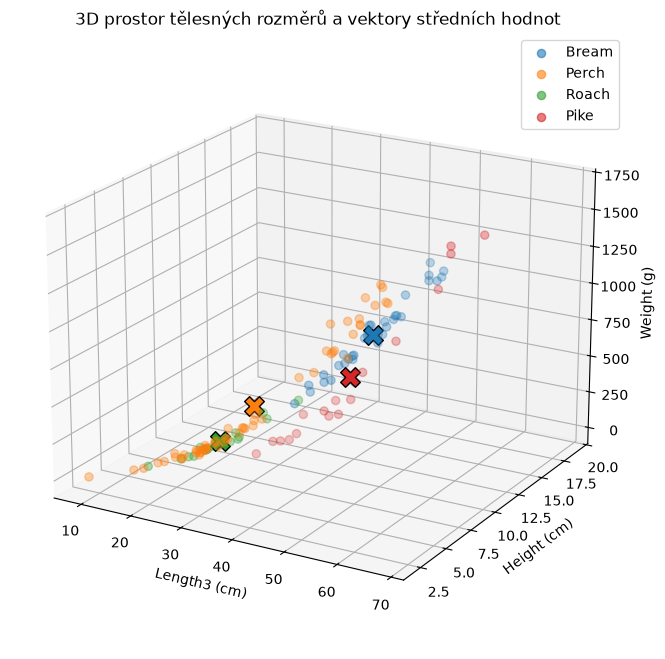

In [54]:
colors = {'Bream': 'tab:blue', 'Perch': 'tab:orange', 'Roach': 'tab:green', 'Pike': 'tab:red'}

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

for sp in classes:
    sub = df[df['Species'] == sp].dropna(subset=variables)
    ax.scatter(sub['Length3'], sub['Height'], sub['Weight'], label=sp, color=colors[sp], alpha=0.6, s=35)
    
    # vektor středních hodnot
    ax.scatter(sub['Length3'].mean(), sub['Height'].mean(), sub['Weight'].mean(), color=colors[sp], marker='X', s=200, edgecolor='black')

ax.set_xlabel('Length3 (cm)')
ax.set_ylabel('Height (cm)')
ax.set_zlabel('Weight (g)')
ax.set_title('3D prostor tělesných rozměrů a vektory středních hodnot')
ax.legend()
ax.view_init(elev=20, azim=-60) # úhel pohledu
plt.show()

Jako poslední test byla provedena vícerozměrná analýza rozptylu MANOVA, předpokládající vícerozměrnou normalitu a shodné varianční matice ve všech skupinách, kterou zvolená data nesplňují, je tedy nutné test považovat za orientační, a z testovacích statistik které knihovna počítá se zaměřit hlavně na Pillaiovu stopu, která je nejvhodnější statistikou při nesplnění předpokladů.
* $H_0: \boldsymbol{\mu}_i = \boldsymbol{\mu}_1 = \boldsymbol{\mu}_2 = \boldsymbol{\mu}_3 = \boldsymbol{\mu}_4$
* $H_1: \boldsymbol{\mu}_i \neq \boldsymbol{\mu}_j$

In [55]:
from statsmodels.multivariate.manova import MANOVA

df_manova = df[df['Species'].isin(classes)].dropna(subset=variables)

# MANOVA pro 3 zvolené proměnné a 4 druhy
manova_model = MANOVA.from_formula('Length3 + Height + Weight ~ C(Species)', data=df_manova)
print(manova_model.mv_test())

                   Multivariate linear model
                                                                
----------------------------------------------------------------
       Intercept         Value  Num DF  Den DF   F Value  Pr > F
----------------------------------------------------------------
          Wilks' lambda  0.0247 3.0000 121.0000 1592.1455 0.0000
         Pillai's trace  0.9753 3.0000 121.0000 1592.1455 0.0000
 Hotelling-Lawley trace 39.4747 3.0000 121.0000 1592.1455 0.0000
    Roy's greatest root 39.4747 3.0000 121.0000 1592.1455 0.0000
----------------------------------------------------------------
                                                                
----------------------------------------------------------------
        C(Species)        Value  Num DF  Den DF  F Value  Pr > F
----------------------------------------------------------------
           Wilks' lambda  0.0168 9.0000 294.6328 142.8279 0.0000
          Pillai's trace  1.6822 9.0000 369.0

Nulovou hypotézu o shodě vektorů středních hodnot všech čtyř druhů ryb opět jednoznačně zamítáme. To potvrzuje tvrzení předchozích testů, že druh ryby má statisticky vysoce významný vliv na trojrozměrný vektor tělesných rozměrů, což dává i logický smysl.